# 02 · Map the Yanbaru Kuina with hexagons

Start here with the included CSV and run the cells from the Day 20 folder. Notebook 01 explains how the CSV was made.

Run one cell at a time with Shift+Enter. Check the survey counts after loading the CSV. To try a different hexagon size, change HEX_RADIUS_METRES in the first code cell and run all cells again.

The last cell writes media/yanbaru_kuina_hexagons.png. The bird is a separate PNG.

## 1. Set the map options

The radius is the distance from a hexagon’s centre to a corner. Both years use the same radius and grid. Edit the title, subtitle or radius here.

In [9]:
import csv
from io import BytesIO
from pathlib import Path
from urllib.error import HTTPError
from urllib.request import Request, urlopen
from zipfile import ZipFile

import geopandas as gpd
import matplotlib.patheffects as effects
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle, RegularPolygon
from PIL import Image
from pyproj import Transformer
from shapely import get_parts
from shapely.geometry import box
from shapely.ops import polylabel

COAST_URL = (
    "https://nlftp.mlit.go.jp/ksj/gml/data/N03/N03-2024/"
    "N03-20240101_47_GML.zip"
)
COAST_MEMBER = "N03-20240101_47.geojson"
HILLSHADE_URL = "https://cyberjapandata.gsi.go.jp/xyz/hillshademap/{z}/{x}/{y}.png"
# Change these settings to try a different grid size or title.
YEARS = (2007, 2024)
HEX_RADIUS_METRES = 1_300
TITLE = "The Yanbaru Kuina Makes a Comeback"
SUBTITLE = "Endangered Okinawa Rail detections in Northern Okinawa, Japan"
DATA_FILE = Path("data/yanbaru_kuina_survey_cells.csv")
OUTPUT = Path("media/yanbaru_kuina_hexagons.png")


def download(url):
    request = Request(url, headers={"User-Agent": "Day20-MapChallenge/1.0"})
    with urlopen(request, timeout=90) as response:
        return response.read()

## 2. Load the survey squares

Each CSV row gives the year, the estimated centre of a survey square, and a detection flag. A flag of 1 means the rail was detected. A flag of 0 means surveyors looked without a detection.

We convert longitude and latitude to UTM zone 52N so X and Y are in metres. You should see 190 survey squares in 2007 and 261 in 2024.

In [10]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Run 01_create_survey_dataset.ipynb to make {DATA_FILE}.")

to_metres = Transformer.from_crs("EPSG:4326", "EPSG:32652", always_xy=True)
surveys = {year: [] for year in YEARS}
with DATA_FILE.open(encoding="utf-8", newline="") as file:
    for row in csv.DictReader(file):
        year = int(row["survey_year"])
        if year not in surveys:
            continue
        longitude = float(row["cell_center_lon"])
        latitude = float(row["cell_center_lat"])
        detected = int(row["rail_detected"])
        if detected not in (0, 1):
            raise ValueError(f"rail_detected must be 0 or 1. Got {detected} in {year}.")
        east, north = to_metres.transform(longitude, latitude)
        surveys[year].append((east, north, detected))

for year, cells in surveys.items():
    if not cells:
        raise ValueError(f"No survey squares available for {year}.")
    print(f"{year}: {len(cells)} survey squares, {sum(cell[2] for cell in cells)} with a detection")

2007: 190 survey squares, 102 with a detection
2024: 261 survey squares, 199 with a detection


## 3. Build one hexagon grid

Get the full extent of the survey squares from both years. Make a grid wide enough to cover it. Move alternate columns up by half a row so the hexagons fit together.

In [11]:
radius = HEX_RADIUS_METRES
column_spacing = 1.5 * radius
row_spacing = np.sqrt(3) * radius
all_cells = np.asarray([cell[:2] for cells in surveys.values() for cell in cells])
lower, upper = all_cells.min(axis=0), all_cells.max(axis=0)
column_min = int(np.floor(lower[0] / column_spacing)) - 1
column_max = int(np.ceil(upper[0] / column_spacing)) + 1
row_min = int(np.floor(lower[1] / row_spacing)) - 1
row_max = int(np.ceil(upper[1] / row_spacing)) + 1

centres = np.asarray([
    (column * column_spacing, (row + 0.5 * (column % 2)) * row_spacing)
    for column in range(column_min, column_max + 1)
    for row in range(row_min, row_max + 1)
])

## 4. Count detections in each hexagon

Find the hexagon centre closest to each survey square’s centre. Add the square’s 0 or 1 to that hexagon. For example, two squares with detections and one without give a total of 2.

A total of 0 means the hexagon has survey results and all were non-detections. A hexagon with no survey records has no entry in the results. The legend shows both cases.

In [12]:
hexes = {}
for year, cells in surveys.items():
    assigned = {}
    for east, northing, detected in cells:
        offsets = centres - (east, northing)
        squared_distances = (offsets ** 2).sum(axis=1)
        index = int(squared_distances.argmin())
        assigned[index] = assigned.get(index, 0) + int(detected)
    hexes[year] = assigned
    confirmed_cells = sum(assigned.values())
    if confirmed_cells != sum(cell[2] for cell in cells):
        raise ValueError(f"Hex aggregation did not preserve the confirmed cell count for {year}.")
    print(
        f"FY {year} | {confirmed_cells} confirmed survey cells across "
        f"{sum(count > 0 for count in assigned.values())} of {len(assigned)} surveyed hexagons. "
        f"Maximum per hexagon: {max(assigned.values())}."
    )

FY 2007 | 102 confirmed survey cells across 50 of 72 surveyed hexagons. Maximum per hexagon: 4.
FY 2024 | 199 confirmed survey cells across 83 of 94 surveyed hexagons. Maximum per hexagon: 6.


## 5. Add the coast and terrain

These two cells add geographic context. The first loads the coastline and municipal boundaries. The second downloads terrain tiles and puts them into the same projection as the survey squares.

In [13]:
bbox = (127.97, 26.54, 128.395, 26.94)
with ZipFile(BytesIO(download(COAST_URL))) as archive:
    municipalities = gpd.read_file(BytesIO(archive.read(COAST_MEMBER)), bbox=bbox)

# Preserve municipal divisions for context and dissolve a copy for the coastline.
municipal_areas = (
    municipalities[["N03_007", "geometry"]].dissolve(by="N03_007").to_crs("EPSG:32652")
)
municipal_lines = municipal_areas.boundary
land = municipalities.geometry.union_all().intersection(box(*bbox))
coast = gpd.GeoSeries([land], crs=municipalities.crs).to_crs("EPSG:32652")

In [14]:
xlim = (lower[0] - 4_000, upper[0] + 4_000)
ylim = (lower[1] - 4_100, upper[1] + 2_900)
utm_to_web = Transformer.from_crs("EPSG:32652", "EPSG:3857", always_xy=True)
zoom = 12
tile_size = 256
canvas_size = 480
utm_x = xlim[0] + (np.arange(canvas_size) + 0.5) * (xlim[1] - xlim[0]) / canvas_size
utm_y = ylim[1] - (np.arange(canvas_size) + 0.5) * (ylim[1] - ylim[0]) / canvas_size
mx, my = utm_to_web.transform(*np.meshgrid(utm_x, utm_y))
web_extent = 20_037_508.342789244
pixels_per_metre = (tile_size * 2**zoom) / (2 * web_extent)
px = np.floor((mx + web_extent) * pixels_per_metre).astype(int)
py = np.floor((web_extent - my) * pixels_per_metre).astype(int)
tile_x, tile_y = px // tile_size, py // tile_size
relief = np.zeros((canvas_size, canvas_size, 4), dtype=float)
relief[..., :3] = (0.25, 0.29, 0.26)
for tx, ty in np.unique(np.column_stack([tile_x.ravel(), tile_y.ravel()]), axis=0):
    try:
        payload = download(HILLSHADE_URL.format(z=zoom, x=tx, y=ty))
    except HTTPError as error:
        if error.code != 404:
            raise
        continue  # GSI omits ocean-only tiles.
    with Image.open(BytesIO(payload)) as tile:
        rgba = np.asarray(tile.convert("RGBA"), dtype=float) / 255
    mask = (tile_x == tx) & (tile_y == ty)
    samples = rgba[py[mask] % tile_size, px[mask] % tile_size]
    relief[mask, 3] = samples[:, 3] * (1 - samples[:, :3].mean(axis=1)) * 0.48

## 6. Draw the two map panels

Make one green scale from the maximum count across both years. Use hatched ochre for surveyed hexagons with zero detections. Draw the coast, place labels and scale bars in both panels.

In [15]:
paper, sea, land_fill = "#f6f3e9", "#eef2eb", "#e2e6d7"
ink, muted = "#1b3029", "#4e6057"
surveyed_fill = "#e8d2a5"
maximum_count = max(max(counts.values()) for counts in hexes.values())
ramp = LinearSegmentedColormap.from_list(
    "yanbaru", ["#c9e2a8", "#77b775", "#2c8057", "#0a483a"],
)
greens = ramp(np.linspace(0, 1, maximum_count))
fill_by_count = [surveyed_fill, *greens]

fig = plt.figure(figsize=(11.4, 8), facecolor=paper)
# Panel positions follow the supplied layout at the 2736 × 1920 export size.
axes = [
    fig.add_axes([left, 0.21654, 0.3740, 0.582])
    for left in (0.09137, 0.48026)
]
fig.text(0.065, 0.89354, TITLE,
         fontsize=31, fontfamily="DejaVu Serif", weight="bold", color=ink)
fig.text(0.22782, 0.85331, SUBTITLE,
         fontsize=12, color="#aa2832")

labels = [
    ("Cape Hedo", (128.257, 26.872), (0.45, 0.94)),
    ("Yanbaru Forest", (128.240, 26.761), (0.09, 0.68)),
]
municipal_labels = [
    ("Kunigami", "47301", (0.96, 0.77), "right"),
    ("Ōgimi", "47302", (0.15, 0.35), "left"),
    ("Higashi", "47303", (0.96, 0.28), "right"),
    ("Nago", "47209", (0.09, 0.13), "left"),
]
view = box(xlim[0], ylim[0], xlim[1], ylim[1])
placed_labels = []
for name, code, position, alignment in municipal_labels:
    visible_land = municipal_areas.geometry.loc[code].intersection(view)
    main_part = max(get_parts(visible_land), key=lambda part: part.area)
    # Use the point farthest from the edge of the main visible land area.
    anchor = polylabel(main_part, tolerance=50)
    placed_labels.append((name, (anchor.x, anchor.y), position, alignment))

municipal_ink = "#733559"
for ax, year in zip(axes, YEARS):
    ax.set_facecolor(sea)
    coast.plot(ax=ax, facecolor=land_fill, edgecolor="none", zorder=1)
    ax.imshow(relief, extent=(*xlim, *ylim), interpolation="bilinear", zorder=2)
    for index, count in hexes[year].items():
        ax.add_patch(RegularPolygon(
            centres[index], numVertices=6, radius=radius,
            orientation=np.pi / 6, facecolor=fill_by_count[count],
            edgecolor="#826c49" if count == 0 else paper, linewidth=0.58,
            hatch="///" if count == 0 else None, alpha=1.0 if count == 0 else 0.87,
            zorder=3,
        ))
    municipal_lines.plot(ax=ax, color="#59665e", linewidth=0.66, linestyle=(0, (2, 2)),
                         alpha=0.62, zorder=4)
    coast.boundary.plot(ax=ax, color="#62736a", linewidth=0.60, zorder=4)
    for name, location, label_position in labels:
        ax.annotate(
            name, xy=to_metres.transform(*location), xycoords="data",
            xytext=label_position, textcoords="axes fraction",
            fontsize=8.4, color=ink, va="center",
            path_effects=[effects.withStroke(linewidth=2.4, foreground=sea)],
            arrowprops={"arrowstyle": "-", "color": "#65756b", "lw": 0.68},
            zorder=6,
        )
    for name, anchor, position, alignment in placed_labels:
        callout = ax.annotate(
            name, xy=anchor, xytext=position, textcoords="axes fraction",
            ha=alignment, va="center", fontsize=8.2, fontweight="bold", color=municipal_ink,
            path_effects=[effects.withStroke(linewidth=2.6, foreground=sea)],
            arrowprops={"arrowstyle": "-", "color": municipal_ink, "lw": 1.15, "shrinkB": 0},
            zorder=6,
        )
        callout.arrow_patch.set_path_effects(
            [effects.withStroke(linewidth=2.5, foreground=sea)]
        )
        ax.plot(*anchor, marker="o", markersize=4.5, markerfacecolor=municipal_ink,
                markeredgecolor=sea, markeredgewidth=0.8, zorder=7)
    ax.text(0.08, 0.49, "East China Sea", transform=ax.transAxes,
            fontsize=8.5, color="#687b71", fontstyle="italic", zorder=5)
    ax.set(xlim=xlim, ylim=ylim, aspect="equal", xticks=[], yticks=[], xlabel="", ylabel="")
    for spine in ax.spines.values():
        spine.set_color("#c9d3c9")
        spine.set_linewidth(0.7)
    ax.text(0.045, 0.955, str(year), transform=ax.transAxes, ha="left", va="top",
            fontsize=24, color=ink, weight="bold", fontfamily="DejaVu Serif")
    n = sum(hexes[year].values())
    ax.text(0.047, 0.865, f"{n} survey cells with detections", transform=ax.transAxes,
            ha="left", va="top", fontsize=9, color=muted)
    ax.annotate("N", xy=(0.905, 0.925), xytext=(0.905, 0.955),
                xycoords="axes fraction", textcoords="axes fraction",
                arrowprops={"arrowstyle": "<|-", "color": muted, "lw": 0.8},
                ha="center", va="bottom", fontsize=8, color=muted)
    scale_x = xlim[1] - 7_700
    scale_y = ylim[0] + 2_350
    segment = 2_500
    for offset, face in ((0, muted), (segment, paper)):
        ax.add_patch(Rectangle(
            (scale_x + offset, scale_y), segment, 230,
            facecolor=face, edgecolor=muted, linewidth=0.7,
        ))
    for offset, label in ((0, "0"), (segment, "2.5"), (2 * segment, "5 km")):
        ax.text(scale_x + offset, scale_y + 490, label,
                ha="center", va="bottom", fontsize=7.5, color=muted)

plt.close(fig)

## 7. Add the legend and export

Add the shared legend, survey coverage note and sources. The last two lines save the map PNG and show the figure.

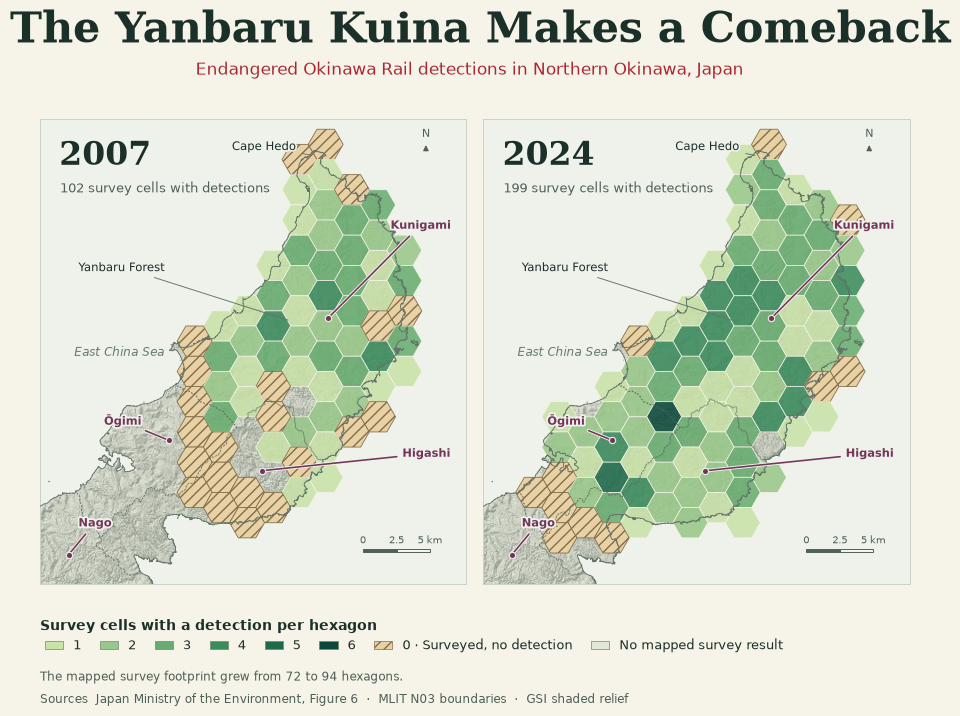

In [16]:
fig.text(0.09137, 0.159, "Survey cells with a detection per hexagon",
         fontsize=10, color=ink, weight="bold")
positive_handles = [
    Patch(facecolor=fill_by_count[count], edgecolor="#748575", linewidth=0.5, label=str(count))
    for count in range(1, maximum_count + 1)
]
zero_handle = Patch(facecolor=surveyed_fill, edgecolor="#826c49", linewidth=0.5,
                    hatch="///", label="0 · Surveyed, no detection")
blank_handle = Patch(facecolor=land_fill, edgecolor="#748575", linewidth=0.5,
                     label="No mapped survey result")
fig.legend(
    handles=[*positive_handles, zero_handle, blank_handle],
    loc="lower left", bbox_to_anchor=(0.09137, 0.125), borderaxespad=0,
    frameon=False, fontsize=9, ncols=maximum_count + 2, labelcolor=ink,
    handlelength=1.45, columnspacing=1.5,
)
footprints = [len(hexes[year]) for year in YEARS]
fig.text(0.09137, 0.09585,
         f"The mapped survey footprint grew from {footprints[0]} to {footprints[1]} hexagons.",
         fontsize=8.5, color=muted)
fig.text(0.09137, 0.06785, "Sources  Japan Ministry of the Environment, Figure 6  ·  MLIT N03 boundaries  ·  GSI shaded relief",
         fontsize=8.5, color=muted)

OUTPUT.parent.mkdir(exist_ok=True)
fig.savefig(OUTPUT, dpi=240, facecolor=fig.get_facecolor())
fig